In [1]:
import pandas as pd

df = pd.read_csv("../data/ab_data.csv")
countries = pd.read_csv("../data/countries.csv")

print(df.shape)
print(df.head())
print(df.dtypes)
print(df["group"].value_counts())
print(df["landing_page"].value_counts())
print(pd.crosstab(df["group"], df["landing_page"]))
print(df["user_id"].nunique())


(294478, 5)
   user_id                   timestamp      group landing_page  converted
0   851104  2017-01-21 22:11:48.556739    control     old_page          0
1   804228  2017-01-12 08:01:45.159739    control     old_page          0
2   661590  2017-01-11 16:55:06.154213  treatment     new_page          0
3   853541  2017-01-08 18:28:03.143765  treatment     new_page          0
4   864975  2017-01-21 01:52:26.210827    control     old_page          1
user_id         int64
timestamp         str
group             str
landing_page      str
converted       int64
dtype: object
group
treatment    147276
control      147202
Name: count, dtype: int64
landing_page
old_page    147239
new_page    147239
Name: count, dtype: int64
landing_page  new_page  old_page
group                           
control           1928    145274
treatment       145311      1965
290584


In [2]:
mismatch = (df["group"] == "treatment") != (df["landing_page"] == "new_page")
print("Mismatched rows:", mismatch.sum())

dupes = df[df["user_id"].duplicated(keep=False)]
print("Rows belonging to duplicated users:", len(dupes))
print("Duplicated users:", dupes["user_id"].nunique())

print(dupes.sort_values("user_id").head(10))


Mismatched rows: 3893
Rows belonging to duplicated users: 7788
Duplicated users: 3894
        user_id                   timestamp      group landing_page  converted
213114   630052  2017-01-07 12:25:54.089486  treatment     old_page          1
230259   630052  2017-01-17 01:16:05.208766  treatment     new_page          0
251762   630126  2017-01-19 17:16:00.280440  treatment     new_page          0
22513    630126  2017-01-14 13:35:54.778695  treatment     old_page          0
11792    630137  2017-01-22 14:59:22.051308    control     new_page          0
183371   630137  2017-01-20 02:08:49.893878    control     old_page          0
255753   630320  2017-01-12 05:27:37.181803  treatment     old_page          0
207211   630320  2017-01-07 18:02:43.626318    control     old_page          0
110634   630471  2017-01-23 01:42:51.501851    control     old_page          0
96929    630471  2017-01-07 02:14:17.405726    control     new_page          0


In [3]:
# 1. Drop rows where group and landing page don't match
df_clean = df[~mismatch].copy()
print("After dropping mismatches:", df_clean.shape, "| unique users:", df_clean["user_id"].nunique())

# 2. Look at the remaining true duplicate
print(df_clean[df_clean["user_id"].duplicated(keep=False)])

# 3. Convert timestamp, keep each user's earliest visit
df_clean["timestamp"] = pd.to_datetime(df_clean["timestamp"])
df_clean = df_clean.sort_values("timestamp").drop_duplicates(subset="user_id", keep="first")

print("Final:", df_clean.shape, "| unique users:", df_clean["user_id"].nunique())
print(pd.crosstab(df_clean["group"], df_clean["landing_page"]))

After dropping mismatches: (290585, 5) | unique users: 290584
      user_id                   timestamp      group landing_page  converted
1899   773192  2017-01-09 05:37:58.781806  treatment     new_page          0
2893   773192  2017-01-14 02:55:59.590927  treatment     new_page          0
Final: (290584, 5) | unique users: 290584
landing_page  new_page  old_page
group                           
control              0    145274
treatment       145310         0


## Data cleaning

- 3,893 rows had a group/page mismatch (control users shown the new page, or treatment users shown the old page). Since I can't know which experience these users actually got, they were dropped.
- The mismatches were split evenly across groups (1,928 control vs 1,965 treatment) and made up ~1.3% of rows, so removing them shouldn't bias the comparison.
- One user had two identical valid visits; the earliest was kept as their first exposure.
- Final dataset: 290,584 unique users.

In [4]:
# Join countries
df_clean = df_clean.merge(countries, on="user_id", how="left")
print("Missing countries:", df_clean["country"].isna().sum())
print(df_clean["country"].value_counts())

# First look at conversion by group
print(df_clean.groupby("group")["converted"].agg(["count", "mean"]))

Missing countries: 0
country
US    203619
UK     72466
CA     14499
Name: count, dtype: int64
            count      mean
group                      
control    145274  0.120386
treatment  145310  0.118808


In [5]:
from scipy.stats import chisquare

observed = df_clean["group"].value_counts().sort_index()
expected = [len(df_clean) / 2, len(df_clean) / 2]

stat, p_value = chisquare(f_obs=observed, f_exp=expected)

print(observed)
print(f"Chi-square statistic: {stat:.4f}")
print(f"p-value: {p_value:.4f}")

group
control      145274
treatment    145310
Name: count, dtype: int64
Chi-square statistic: 0.0045
p-value: 0.9468


## Experiment health check: sample ratio mismatch

A chi-square goodness-of-fit test compared the observed group sizes (145,274 control vs 145,310 treatment) to the expected 50/50 split. With p = 0.95, there's no evidence of sample ratio mismatch: the assignment looks healthy and the groups are comparable in size.


In [6]:
from scipy.stats import chi2_contingency

country_table = pd.crosstab(df_clean["group"], df_clean["country"])
print(country_table)
print()
print(pd.crosstab(df_clean["group"], df_clean["country"], normalize="index").round(4))

stat, p_value, dof, expected = chi2_contingency(country_table)
print(f"\nChi-square statistic: {stat:.4f}")
print(f"p-value: {p_value:.4f}")

country      CA     UK      US
group                         
control    7198  36360  101716
treatment  7301  36106  101903

country        CA      UK      US
group                            
control    0.0495  0.2503  0.7002
treatment  0.0502  0.2485  0.7013

Chi-square statistic: 1.7893
p-value: 0.4088


## Experiment health check: country balance

A chi-square test of independence between group and country found no relationship (p = 0.41). Both groups have nearly the same country mix (~70% US, ~25% UK, ~5% CA), so differences in conversion can't be explained by one group getting more users from a particular country.

In [8]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

baseline = df_clean[df_clean["group"] == "control"]["converted"].mean()
n_per_group = df_clean["group"].value_counts().min()

analysis = NormalIndPower()
effect = analysis.solve_power(nobs1=n_per_group, alpha=0.05, power=0.8, ratio=1.0)

# Convert the effect size back into a conversion rate
from scipy.optimize import brentq
target = brentq(lambda p: proportion_effectsize(p, baseline) - effect, baseline, baseline + 0.05)

print(f"Baseline conversion: {baseline:.4%}")
print(f"Users per group: {n_per_group:,}")
print(f"Minimum detectable rate: {target:.4%}")
print(f"MDE (absolute): {target - baseline:.4%} points")
print(f"MDE (relative): {(target - baseline) / baseline:.2%}")

Baseline conversion: 12.0386%
Users per group: 145,274
Minimum detectable rate: 12.3789%
MDE (absolute): 0.3403% points
MDE (relative): 2.83%


## Power analysis: minimum detectable effect

With ~145,000 users per group, a 12.04% baseline conversion rate, α = 0.05, and 80% power, the smallest lift this test could reliably detect is **0.34 percentage points** (12.04% → 12.38%, or 2.83% relative).

This sets the bar for interpreting the result: if the test finds no significant difference, we can be reasonably confident the new page didn't improve conversion by 0.34 points or more. Smaller real effects could still exist undetected.

In [9]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

conversions = df_clean.groupby("group")["converted"].sum()
users = df_clean.groupby("group")["converted"].count()

# Order: treatment first, control second, so the difference is treatment minus control
count = [conversions["treatment"], conversions["control"]]
nobs = [users["treatment"], users["control"]]

z_stat, p_value = proportions_ztest(count, nobs, alternative="two-sided")
ci_low, ci_high = confint_proportions_2indep(count[0], nobs[0], count[1], nobs[1])

rate_t = count[0] / nobs[0]
rate_c = count[1] / nobs[1]

print(f"Control rate:   {rate_c:.4%}")
print(f"Treatment rate: {rate_t:.4%}")
print(f"Difference:     {rate_t - rate_c:.4%} points")
print(f"z-statistic:    {z_stat:.4f}")
print(f"p-value:        {p_value:.4f}")
print(f"95% CI for difference: [{ci_low:.4%}, {ci_high:.4%}]")

Control rate:   12.0386%
Treatment rate: 11.8808%
Difference:     -0.1578% points
z-statistic:    -1.3109
p-value:        0.1899
95% CI for difference: [-0.3938%, 0.0781%]


## Main result: two-proportion z-test

| | Control (old page) | Treatment (new page) |
|---|---|---|
| Users | 145,274 | 145,310 |
| Conversion rate | 12.04% | 11.88% |

- **Difference:** −0.16 percentage points (new minus old)
- **z = −1.31, p = 0.19** (two-sided)
- **95% CI for the difference:** [−0.39, +0.08] points

The new page did not produce a statistically significant change in conversion. The confidence interval includes zero, and its upper end (+0.08 points) is well below the test's minimum detectable effect of 0.34 points. In the best case, the new page offers no meaningful improvement, and the point estimate leans slightly negative.

In [10]:
countries_list = ["US", "UK", "CA"]
alpha_corrected = 0.05 / len(countries_list)

rows = []
for c in countries_list:
    seg = df_clean[df_clean["country"] == c]
    conv = seg.groupby("group")["converted"].sum()
    n = seg.groupby("group")["converted"].count()

    count = [conv["treatment"], conv["control"]]
    nobs = [n["treatment"], n["control"]]

    z, p = proportions_ztest(count, nobs, alternative="two-sided")
    lo, hi = confint_proportions_2indep(count[0], nobs[0], count[1], nobs[1])

    rows.append({
        "country": c,
        "users": n.sum(),
        "control_rate": count[1] / nobs[1],
        "treatment_rate": count[0] / nobs[0],
        "difference": count[0] / nobs[0] - count[1] / nobs[1],
        "ci_low": lo,
        "ci_high": hi,
        "p_value": p,
        "significant": p < alpha_corrected,
    })

country_results = pd.DataFrame(rows)
print(f"Bonferroni-corrected cutoff: {alpha_corrected:.4f}\n")
print(country_results.round(4))

Bonferroni-corrected cutoff: 0.0167

  country   users  control_rate  treatment_rate  difference  ci_low  ci_high  \
0      US  203619        0.1206          0.1185     -0.0022 -0.0050   0.0007   
1      UK   72466        0.1200          0.1212      0.0011 -0.0036   0.0059   
2      CA   14499        0.1188          0.1119     -0.0069 -0.0173   0.0035   

   p_value  significant  
0   0.1323        False  
1   0.6349        False  
2   0.1947        False  


## Segment analysis: by country

The z-test was repeated within each country, using a Bonferroni-corrected cutoff of 0.05 / 3 = 0.0167 to account for running multiple tests.

| Country | Users | Difference (new − old) | 95% CI | p-value |
|---|---|---|---|---|
| US | 203,619 | −0.22 pts | [−0.50, +0.07] | 0.13 |
| UK | 72,466 | +0.11 pts | [−0.36, +0.59] | 0.63 |
| CA | 14,499 | −0.69 pts | [−1.73, +0.35] | 0.19 |

No country showed a significant effect, even before the correction. The UK's slightly positive difference is within normal noise (p = 0.63), and Canada's wide interval reflects its small sample. The overall null result holds across all three markets.

Python(77121) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(77122) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Matplotlib is building the font cache; this may take a moment.


Date range: 2017-01-02 to 2017-01-24
Days: 23


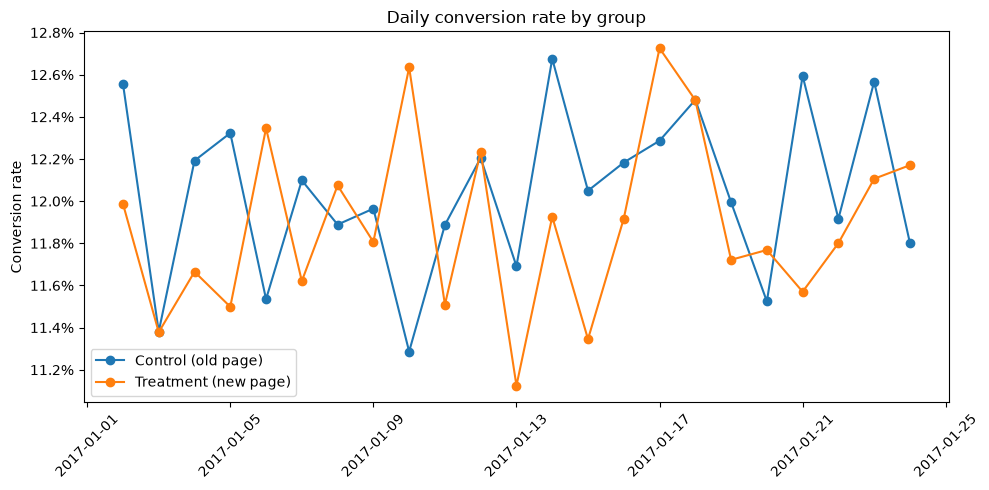

In [11]:
import matplotlib.pyplot as plt

df_clean["date"] = df_clean["timestamp"].dt.date
daily = df_clean.groupby(["date", "group"])["converted"].mean().unstack()

print(f"Date range: {df_clean['date'].min()} to {df_clean['date'].max()}")
print(f"Days: {daily.shape[0]}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(daily.index, daily["control"], marker="o", label="Control (old page)")
ax.plot(daily.index, daily["treatment"], marker="o", label="Treatment (new page)")
ax.set_title("Daily conversion rate by group")
ax.set_ylabel("Conversion rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../figures/daily_conversion.png", dpi=150)
plt.show()

## Segment analysis: over time

Daily conversion rates were plotted for each group across the 23-day test (Jan 2–24, 2017) to check for novelty effects (an early boost that fades) or change aversion (an early dip that recovers).

![Daily conversion rate by group](../figures/daily_conversion.png)

The two lines cross repeatedly with no consistent pattern: the old page leads on some days early and late, and the new page leads on others. There's no sign of the gap narrowing or widening over time. Daily rates swing about ±0.8 points from noise alone (~6,300 users per group per day), so this check can only rule out a strong time effect, not a subtle one.